# Week 8, Task 5: Stress-testing the emulator

We run the team's week-7 NN emulator (5-seed ensemble, `week7/cheryl/results/emulator.pkl`) on three scenarios it never saw. Each one branches from ssp245:

| Scenario | CO₂ (cumulative) | CH₄ | SO₂, BC |
|---|---|---|---|
| **zero2030**: all emissions stop in 2030 | frozen at its 2029 value | 0 from 2030 | 0 from 2030 |
| **fixed2015**: emissions held at 2015 levels | grows by the 2015 annual rate every year | 2015 value | 2015 maps |
| **noaer2030**: SO₂ and BC removed in 2030 | ssp245 | ssp245 | 0 from 2030 |

For each scenario we check three things against physical expectations: **sign, size and timescale**. We also check whether the inputs leave the region the emulator was trained on.

Only the emulator pickle and `inputs_ssp245.nc` are needed; no retraining.

In [1]:
import pickle
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import jax, jax.numpy as jnp

EMULATOR_PKL = "../../week7/cheryl/results/emulator.pkl"
SSP245_INPUTS = "../../week7/jennifer/inputs_ssp245.nc"
START, END = 2081, 2100
BREAK = 2030

## Load the emulator and rebuild `emulate()`
This is the same `features` → MLP → PCA-pattern pipeline as in week 7, rebuilt from the pickle.

In [2]:
with open(EMULATOR_PKL, "rb") as f:
    E = pickle.load(f)
PRE = {k: jnp.asarray(v) for k, v in E["pre"].items()}
STACKED = jax.tree_util.tree_map(jnp.asarray, E["params"])
NLAT, NLON, lat, lon = E["nlat"], E["nlon"], np.asarray(E["lat"]), np.asarray(E["lon"])

def features(co2, ch4, so2, bc):
    T = co2.shape[0]
    so2_f = (so2.reshape(T, -1) - PRE["so2_mean"]) @ PRE["so2_pcs"].T
    bc_f  = (bc.reshape(T, -1)  - PRE["bc_mean"])  @ PRE["bc_pcs"].T
    return jnp.concatenate([co2[:, None], ch4[:, None], so2_f, bc_f], axis=1)

def zfeatures(co2, ch4, so2, bc):
    """Standardized features: what the network actually sees."""
    return (features(co2, ch4, so2, bc) - PRE["f_mean"]) / PRE["f_std"]

def mlp(params, x):
    *layers, skip = params
    h = x
    for layer in layers[:-1]:
        h = jnp.tanh(h @ layer["W"] + layer["b"])
    return h @ layers[-1]["W"] + layers[-1]["b"] + x @ skip["W"] + skip["b"]

def predict(params, co2, ch4, so2, bc):
    coeffs = mlp(params, zfeatures(co2, ch4, so2, bc)) * PRE["c_std"]
    return (PRE["tas_mean"] + coeffs @ PRE["tas_pcs"]).reshape(co2.shape[0], NLAT, NLON)

@jax.jit
def emulate_members(co2, ch4, so2, bc):
    """(n_seeds, T, lat, lon), used for the seed spread."""
    return jax.vmap(lambda p: predict(p, co2, ch4, so2, bc))(STACKED)

def emulate(co2, ch4, so2, bc):
    return emulate_members(co2, ch4, so2, bc).mean(0)

w = np.cos(np.deg2rad(lat))[:, None] * np.ones((1, NLON))
area_w = jnp.asarray(w / w.mean())
def gmean(x):
    return (x * area_w).mean((-2, -1))
print("seeds in ensemble:", jax.tree_util.tree_leaves(STACKED)[0].shape[0])

seeds in ensemble: 5


## Build the scenarios

In [3]:
X = xr.open_dataset(SSP245_INPUTS)
years = X.time.values
base = {
    "co2": jnp.asarray(X["CO2"].values, jnp.float32),   # cumulative GtCO2 since 1850
    "ch4": jnp.asarray(X["CH4"].values, jnp.float32),
    "so2": jnp.asarray(X["SO2"].transpose("time", ...).values, jnp.float32),
    "bc":  jnp.asarray(X["BC"].transpose("time", ...).values, jnp.float32),
}
after = jnp.asarray(years >= BREAK)
i_brk = int(np.argmax(years >= BREAK))

def zero_from(x):            # zero the field for years >= BREAK
    mask = after.reshape((-1,) + (1,) * (x.ndim - 1))
    return jnp.where(mask, 0.0, x)

# zero2030: cumulative CO2 stops growing, so it stays at its 2029 value
co2_frozen = jnp.where(after, base["co2"][i_brk - 1], base["co2"])
zero2030 = dict(co2=co2_frozen, ch4=zero_from(base["ch4"]),
                so2=zero_from(base["so2"]), bc=zero_from(base["bc"]))

# fixed2015: constant annual emissions at the 2015 rate, so cumulative grows linearly
rate2015 = base["co2"][1] - base["co2"][0]
T = len(years)
fixed2015 = dict(co2=base["co2"][0] + rate2015 * jnp.arange(T, dtype=jnp.float32),
                 ch4=jnp.full(T, base["ch4"][0]),
                 so2=jnp.broadcast_to(base["so2"][0], base["so2"].shape),
                 bc=jnp.broadcast_to(base["bc"][0], base["bc"].shape))

# noaer2030: ssp245 but SO2 and BC removed from 2030
noaer2030 = dict(base, so2=zero_from(base["so2"]), bc=zero_from(base["bc"]))

SCEN = {"ssp245": base, "zero2030": zero2030, "fixed2015": fixed2015, "noaer2030": noaer2030}
print(f"2015 CO2 emission rate: {float(rate2015):.1f} GtCO2/yr")

2015 CO2 emission rate: 36.0 GtCO2/yr


## Run the emulator on every scenario

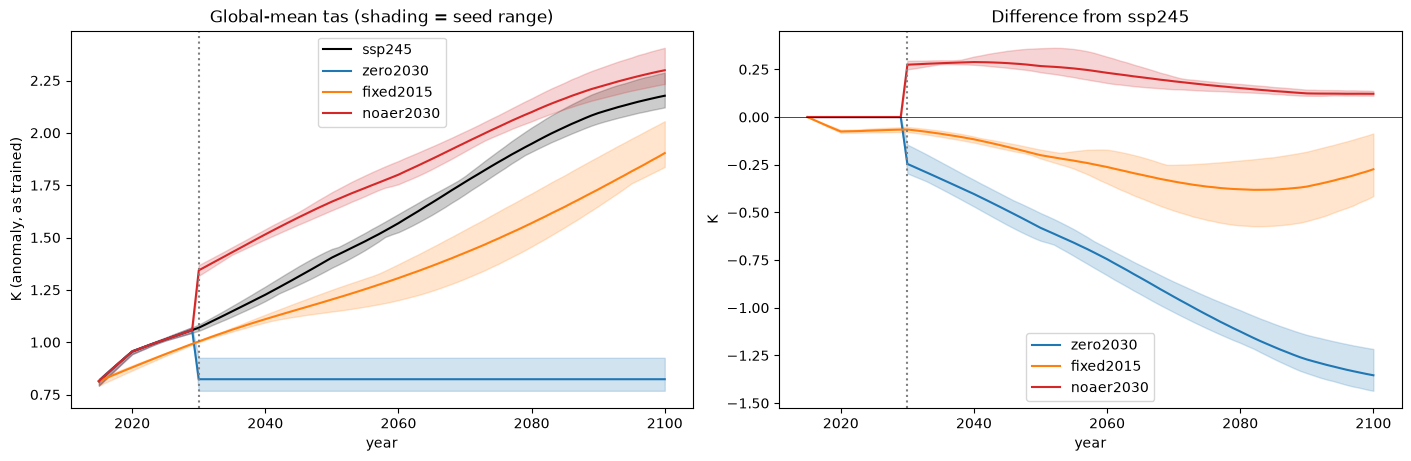

In [4]:
out = {}
for name, s in SCEN.items():
    m = emulate_members(s["co2"], s["ch4"], s["so2"], s["bc"])      # (seed, T, lat, lon)
    out[name] = {"maps": m.mean(0), "gm_members": np.asarray(gmean(m))}
win = (years >= START) & (years <= END)

colors = {"ssp245": "k", "zero2030": "tab:blue", "fixed2015": "tab:orange", "noaer2030": "tab:red"}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
for name, o in out.items():
    gm = o["gm_members"]
    ax[0].plot(years, gm.mean(0), color=colors[name], label=name)
    ax[0].fill_between(years, gm.min(0), gm.max(0), color=colors[name], alpha=0.2)
    if name != "ssp245":
        d = gm - out["ssp245"]["gm_members"]
        ax[1].plot(years, d.mean(0), color=colors[name], label=name)
        ax[1].fill_between(years, d.min(0), d.max(0), color=colors[name], alpha=0.2)
for a in ax:
    a.axvline(BREAK, color="grey", ls=":"); a.set_xlabel("year"); a.legend()
ax[0].set(title="Global-mean tas (shading = seed range)", ylabel="K (anomaly, as trained)")
ax[1].set(title="Difference from ssp245", ylabel="K"); ax[1].axhline(0, color="k", lw=0.5)
plt.savefig("task5_global_mean.png", dpi=150); plt.show()

## Sign, size and timescale
`jump` is the change from 2029 to 2030, the year the perturbation starts. A physical climate takes years to decades to respond, because the ocean has heat capacity and CH₄ has a lifetime of about 12 years.

In [5]:
rows = []
for name in ["zero2030", "fixed2015", "noaer2030"]:
    d = out[name]["gm_members"].mean(0) - out["ssp245"]["gm_members"].mean(0)
    gm = out[name]["gm_members"].mean(0)
    rows.append({
        "scenario": name,
        "jump 2029→2030 (K)": gm[i_brk] - gm[i_brk - 1],
        "Δ vs ssp245, 2030 (K)": d[i_brk],
        "Δ vs ssp245, 2040 (K)": d[years == 2040][0],
        "Δ vs ssp245, 2081–2100 (K)": d[win].mean(),
        "trend 2031–2100 (K/decade)": 10 * np.polyfit(years[i_brk + 1:], gm[i_brk + 1:], 1)[0],
        "seed spread 2081–2100 (K)": np.ptp(out[name]["gm_members"][:, win].mean(1)),
    })
summary = pd.DataFrame(rows).set_index("scenario")
summary.round(3)

,jump 2029→2030 (K),"Δ vs ssp245, 2030 (K)","Δ vs ssp245, 2040 (K)","Δ vs ssp245, 2081–2100 (K)",trend 2031–2100 (K/decade),seed spread 2081–2100 (K)
scenario,,,,,,
zero2030,-0.235,-0.246,-0.404,-1.265,0.000,0.158
fixed2015,0.012,-0.066,-0.117,-0.348,0.126,0.228
noaer2030,0.285,0.274,0.288,0.129,0.139,0.145


### Implied TCRE in the fixed-2015 run
With constant emissions, warming should be close to linear in cumulative CO₂. The slope should match the task-2 TCRE (IPCC: 0.45 K per 1000 GtCO₂, likely range 0.27–0.63). CH₄ and aerosols are held fixed here, so they contribute little to the trend.

In [6]:
gm_fixed = out["fixed2015"]["gm_members"].mean(0)
slope = np.polyfit(np.asarray(fixed2015["co2"]), gm_fixed, 1)[0] * 1000
print(f"fixed2015: dT/d(cumulative CO2) = {slope:.3f} K per 1000 GtCO2")

fixed2015: dT/d(cumulative CO2) = 0.336 K per 1000 GtCO2


## Is the emulator extrapolating?
The network sees standardized features: cumulative CO₂, CH₄, and 5 PCs each of SO₂ and BC. Feature values far outside what ssp245 (a scenario similar to the training data) produces mean the network is extrapolating. On the cluster, compare against the full training-scenario min/max as well.

In [7]:
names = ["CO2", "CH4"] + [f"SO2 PC{i+1}" for i in range(5)] + [f"BC PC{i+1}" for i in range(5)]
Z = {n: np.asarray(zfeatures(s["co2"], s["ch4"], s["so2"], s["bc"])) for n, s in SCEN.items()}
lo, hi = Z["ssp245"].min(0), Z["ssp245"].max(0)
ext = pd.DataFrame({n: np.abs(z).max(0) for n, z in Z.items()}, index=names)
ext["ssp245 range"] = [f"[{a:.2f}, {b:.2f}]" for a, b in zip(lo, hi)]
ext.round(2)

,ssp245,zero2030,fixed2015,noaer2030,ssp245 range
CO2,1.56,0.33,1.59,1.56,"[0.07, 1.56]"
CH4,0.83,1.02,0.78,0.83,"[0.33, 0.83]"
SO2 PC1,0.08,0.10,0.01,0.10,"[-0.01, 0.08]"
SO2 PC2,0.19,0.19,0.19,0.19,"[-0.19, -0.01]"
SO2 PC3,0.06,0.05,0.04,0.05,"[-0.04, 0.06]"
SO2 PC4,0.03,0.02,0.02,0.02,"[-0.03, 0.02]"
SO2 PC5,0.03,0.02,0.02,0.02,"[-0.03, 0.01]"
BC PC1,0.01,0.01,0.01,0.01,"[-0.01, 0.00]"
BC PC2,0.00,0.00,0.00,0.00,"[-0.00, 0.00]"
BC PC3,0.00,0.00,0.00,0.00,"[-0.00, 0.00]"


## Where does the change happen? Maps of the 2081–2100 difference from ssp245

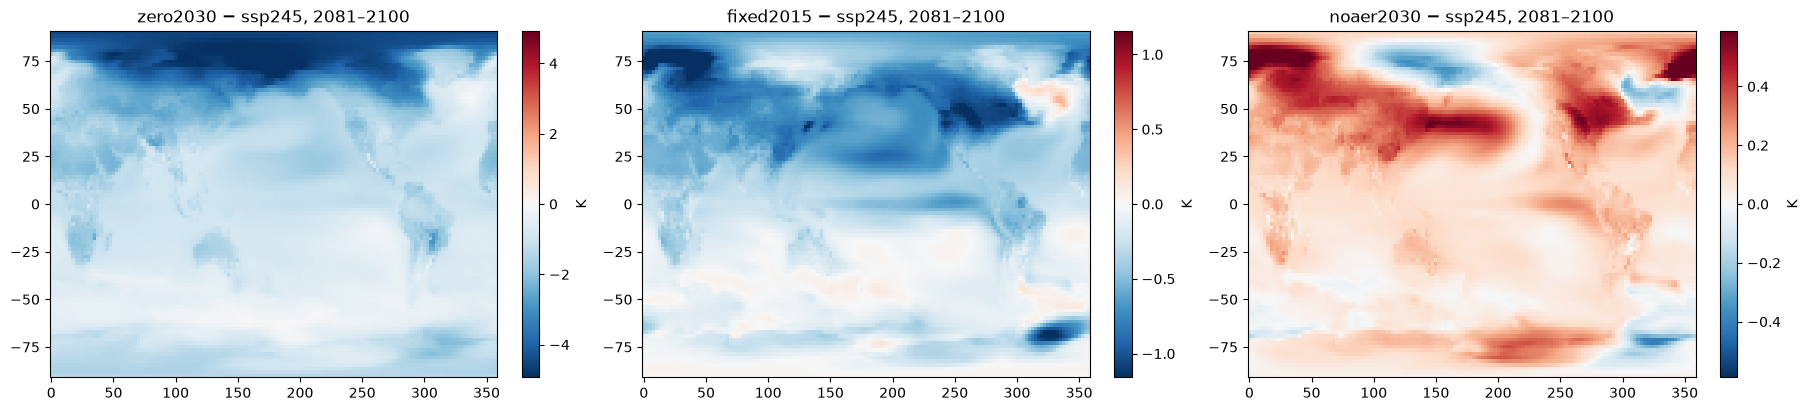

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4), constrained_layout=True)
for a, name in zip(ax, ["zero2030", "fixed2015", "noaer2030"]):
    diff = np.asarray(out[name]["maps"][win].mean(0) - out["ssp245"]["maps"][win].mean(0))
    lim = np.nanpercentile(np.abs(diff), 99)
    m = a.pcolormesh(lon, lat, diff, cmap="RdBu_r", vmin=-lim, vmax=lim)
    a.set_title(f"{name} − ssp245, 2081–2100"); plt.colorbar(m, ax=a, label="K")
plt.savefig("task5_maps.png", dpi=150); plt.show()

## Interpretation (fill in after looking at the numbers above)

**What physics says to expect**
- **zero2030**: with CO₂ alone, warming stays roughly flat after net-zero (the zero-emissions commitment is about 0 ± 0.3 K). Removing aerosols unmasks about 0.3–0.7 K of warming within a few years. Removing CH₄ cools by a few tenths of a K over the following decades. Expect a small bump followed by a slow decline, **not** a step.
- **fixed2015**: cumulative CO₂ grows linearly, so warming should rise steadily at about TCRE × 2015 rate, roughly 0.15–0.2 K/decade, with no levelling off.
- **noaer2030**: warming relative to ssp245 should be largest in the Northern Hemisphere, in and downwind of East and South Asia. It should emerge over a few years and then shrink as ssp245's own aerosol emissions decline.

**Things to check for in the emulator**
1. **Timescale.** The emulator maps each year's inputs to that year's temperature, so it has no memory. Any response should appear as an instantaneous jump in 2030, with no ocean lag and no CH₄ decay. Compare `jump 2029→2030` with the 2040 difference.
2. **Extrapolation.** Zero SO₂ and BC maps, and CH₄ = 0, may lie outside the training features (see the table above). Large |z| or a big seed spread in a scenario means the answer there is unconstrained.
3. **Consistency with TCRE.** Does the fixed2015 slope match the task-2 TCRE?

**What this means for task 4.** The task-4 optimizer only changes cumulative CO₂, the best-constrained input. Its trustworthiness depends on whether the optimized CO₂ path stays inside the training range and whether the CO₂ response here is sensible. Aerosol or CH₄ problems found here would matter more for task 6 (optimizing SO₂).
